In [1]:
## ------- edit params first here --------------

# COSMIC_VER = ['v2','v3']
COSMIC_VER = 'v2'
WES_DB = 'wes-db'
RNA_DB = 'rna-db'
WORKER = None

INPUTROOT = 'export'
OUTPUTROOT = 'report'

# ------------------------------------------------

DBLIBPATH = '[GCpytools_path]'
# RPLOTLIB = '[lib_path]/yutils.R'
# RPLOTLIB = '[lib_path]/yplot.R'

# ------------- optional --------------------------
## utils for plotting
# import seaborn as sns
# sns.set(color_codes=True)
# from matplotlib import pyplot as plt
# from glob import glob

# utils for os.path
from os.path import join as J
from os.path import exists as E
from os import listdir as L
print('global L,E,J is defined')

#---------------- setup PATHs -------------------
## setup WORKDIR
import os
# Change WORKDIR working directory depend on your projext location
WORKDIR = os.getcwd()

## setup OUTPUTPATH and WOKER
import sys

# SET OUTPUT DIR
OUTPUTPATH = os.path.join(WORKDIR,OUTPUTROOT)

if DBLIBPATH not in sys.path:
    sys.path.insert(0,DBLIBPATH)

if WORKDIR != '' :
    if  os.path.exists(WORKDIR):
        os.chdir(WORKDIR)
    else:
        raise ValueError(f'WORKDIR path {WORKDIR} do not exist.')


## setup WOKER
# from dalibs import yglobal
# BASE_HTTP = yglobal.conf['META']['BASE_URL']
# if WORKER is not None:
#     WORKER = yglobal.ypull_current_worker()

# def getcwdurl():
#     p = WORKDIR.replace('[JUP_ROOT]/',BASE_HTTP)
#     print(p)
WORKER = None

#---------------- load librarys -------------------

from tqdm.notebook import tqdm

## to reload modules
# import dalibs
# import importlib
# importlib.reload(dalibs)

## set up db
from dblibs import *
db = Database(outputdir = OUTPUTROOT,input_dir = INPUTROOT, set_used_db=WES_DB)
echo.set(10)
del OUTPUTPATH

#---------------------------------------------------
# getcwdurl()
print(f'[info] Current Worker is >> {WORKER} << working @',os.getcwd())
db

global L,E,J is defined
⚠ dblibs now using custom DBs from package db_utils whose db config file is at [GCpytools_path]/./lib/db_conf.json
⚠ set default global used db to [wes-db]
[info] Current Worker is >> None << working @ [PROJECT_ROOT]


  cur_db_key = wes-db
  OUTPUTDIR = report
  INPUTDIR = export
  Verbose = True

In [1]:
from itertools import combinations

## KEGG hierarchy

In [246]:
kegg = db.importing('external_info/ko00001.json')

kegg


[09/04 08:02:43]reading external_info/ko00001.json


{'name': 'ko00001',
 'children': [{'name': '09100 Metabolism',
   'children': [{'name': '09101 Carbohydrate metabolism',
     'children': [{'name': '00010 Glycolysis / Gluconeogenesis [PATH:ko00010]',
       'children': [{'name': 'K00844  HK; hexokinase [EC:2.7.1.1]'},
        {'name': 'K12407  GCK; glucokinase [EC:2.7.1.2]'},
        {'name': 'K00845  glk; glucokinase [EC:2.7.1.2]'},
        {'name': 'K25026  glk; glucokinase [EC:2.7.1.2]'},
        {'name': 'K01810  GPI, pgi; glucose-6-phosphate isomerase [EC:5.3.1.9]'},
        {'name': 'K06859  pgi1; glucose-6-phosphate isomerase, archaeal [EC:5.3.1.9]'},
        {'name': 'K13810  tal-pgi; transaldolase / glucose-6-phosphate isomerase [EC:2.2.1.2 5.3.1.9]'},
        {'name': 'K15916  pgi-pmi; glucose/mannose-6-phosphate isomerase [EC:5.3.1.9 5.3.1.8]'},
        {'name': 'K24182  PFK9; 6-phosphofructokinase [EC:2.7.1.11]'},
        {'name': 'K00850  pfkA, PFK; 6-phosphofructokinase 1 [EC:2.7.1.11]'},
        {'name': 'K16370  pfkB; 

In [262]:

kegg['children'][0]['name']


'09100 Metabolism'

In [284]:
 kegg['children'][1]['children'][2]['children'][3]['name']
    

'04120 Ubiquitin mediated proteolysis [PATH:ko04120]'

In [316]:
import re

In [318]:
iname = 'Citrate cycle (TCA cycle)'


'CITRATE_CYCLE_TCA_CYCLE'

In [324]:
term

'Citrate_cycle_TCA_cycle'

In [326]:
res = []

for k in range(len(kegg['children'])):
    kl = kegg['children'][k]
    ki = kl['name'][:5]
    kname = kl['name'][6:]
    for j in range(len(kl['children'])):
        jl = kl['children'][j]
        ji = jl['name'][:5]
        jname = jl['name'][6:]
        
        for i in range(len(jl['children'])):
            il = jl['children'][i]
            iname = il['name'][6:].split(' [')[0]
            ii = il['name'][:5]
            term = re.sub('[\(\)\,\-\/]',' ',iname)
            term = 'KEGG_' + re.sub('\s+','_',term.strip()).upper()
            res.append((ki,kname,ji,jname,ii,iname,term))
res = pd.DataFrame(res,columns=['l1_id','l1_name','l2_id','l2_name','l3_id','l3_name','term'])


In [329]:
db.exporting(res, 'KEGG_pathway_classes_hierarchy',outputdir='external_info/')


[09/04 09:08:01] writing 1 file with 551 lines at 
	[PROJECT_ROOT]/external_info/KEGG_pathway_classes_hierarchy.dfx


'[PROJECT_ROOT]/external_info/KEGG_pathway_classes_hierarchy.dfx'

## RNA

In [2]:
sm = db.importing('external_info/PC_canada/sample.PRAD-CA.tsv.gz')
sm


[08/23 01:37:11]reading external_info/PC_canada/sample.PRAD-CA.tsv.gz


,icgc_sample_id,project_code,submitted_sample_id,icgc_specimen_id,submitted_specimen_id,icgc_donor_id,submitted_donor_id,analyzed_sample_interval,percentage_cellularity,level_of_cellularity,study
0,SA598959,PRAD-CA,CPCG0521-F1,SP196079,CPCG0521-F1,DO229393,CPCG0521,NaN,NaN,NaN,NaN
1,SA598991,PRAD-CA,CPCG0521-B1,SP196125,CPCG0521-B1,DO229393,CPCG0521,NaN,NaN,NaN,NaN
2,SA599014,PRAD-CA,CPCG0522-B1,SP196148,CPCG0522-B1,DO229392,CPCG0522,NaN,NaN,NaN,NaN
3,SA598987,PRAD-CA,CPCG0522-F1,SP196121,CPCG0522-F1,DO229392,CPCG0522,NaN,NaN,NaN,NaN
4,SA598830,PRAD-CA,CPCG0402-B1,SP195923,CPCG0402-B1,DO229395,CPCG0402,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
738,SA530488,PRAD-CA,CPCG0263-F1,SP112893,CPCG0263-F1,DO51103,CPCG0263,NaN,60.0,NaN,PCAWG
739,SA530490,PRAD-CA,CPCG0265-B1,SP112894,CPCG0265-B1,DO51104,CPCG0265,NaN,NaN,NaN,PCAWG
740,SA530492,PRAD-CA,CPCG0265-F1,SP112895,CPCG0265-F1,DO51104,CPCG0265,NaN,70.0,NaN,PCAWG
741,SA530496,PRAD-CA,CPCG0266-F1,SP112897,CPCG0266-F1,DO51105,CPCG0266,NaN,80.0,NaN,PCAWG


In [216]:
m2 = sm.set_index('submitted_sample_id')['submitted_donor_id'].to_dict()

In [217]:
matr = db.importing('external_info/PC_canada/exp_seq.PRAD-CA.tsv.gz')
matr['submitted_donor_id'] = [m2[i] for i in matr['submitted_sample_id']]
matr


[08/23 07:42:04]reading external_info/PC_canada/exp_seq.PRAD-CA.tsv.gz


,icgc_donor_id,project_code,icgc_specimen_id,icgc_sample_id,submitted_sample_id,analysis_id,gene_model,gene_id,normalized_read_count,raw_read_count,fold_change,assembly_version,platform,total_read_count,experimental_protocol,alignment_algorithm,normalization_algorithm,other_analysis_algorithm,sequencing_strategy,raw_data_repository,raw_data_accession,reference_sample_type,submitted_donor_id
0,DO229395,PRAD-CA,SP196010,SA598931,CPCG0402-F1,PRAD_CA-WTS,Ensembl,DDX11L1,0.006801,2,NaN,GRCh37,Illumina HiSeq,140296727,NaN,STAR https://github.com/alexdobin/STAR,edgeR https://bioconductor.org/packages/releas...,NaN,RNA-Seq,EGA,EGAF00002212618:EGAF00002212619,NaN,CPCG0402
1,DO229395,PRAD-CA,SP196010,SA598931,CPCG0402-F1,PRAD_CA-WTS,Ensembl,WASH7P,1.503869,157,NaN,GRCh37,Illumina HiSeq,140296727,NaN,STAR https://github.com/alexdobin/STAR,edgeR https://bioconductor.org/packages/releas...,NaN,RNA-Seq,EGA,EGAF00002212618:EGAF00002212619,NaN,CPCG0402
2,DO229395,PRAD-CA,SP196010,SA598931,CPCG0402-F1,PRAD_CA-WTS,Ensembl,RP11-34P13.3,0.000000,0,NaN,GRCh37,Illumina HiSeq,140296727,NaN,STAR https://github.com/alexdobin/STAR,edgeR https://bioconductor.org/packages/releas...,NaN,RNA-Seq,EGA,EGAF00002212618:EGAF00002212619,NaN,CPCG0402
3,DO229395,PRAD-CA,SP196010,SA598931,CPCG0402-F1,PRAD_CA-WTS,Ensembl,FAM138A,0.000000,0,NaN,GRCh37,Illumina HiSeq,140296727,NaN,STAR https://github.com/alexdobin/STAR,edgeR https://bioconductor.org/packages/releas...,NaN,RNA-Seq,EGA,EGAF00002212618:EGAF00002212619,NaN,CPCG0402
4,DO229395,PRAD-CA,SP196010,SA598931,CPCG0402-F1,PRAD_CA-WTS,Ensembl,OR4G4P,0.000000,0,NaN,GRCh37,Illumina HiSeq,140296727,NaN,STAR https://github.com/alexdobin/STAR,edgeR https://bioconductor.org/packages/releas...,NaN,RNA-Seq,EGA,EGAF00002212618:EGAF00002212619,NaN,CPCG0402
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8684347,DO51105,PRAD-CA,SP112897,SA530496,CPCG0266-F1,PRAD_CA-WTS,Ensembl,MT-ND6,75.984615,3247,NaN,GRCh37,Illumina HiSeq,363972631,NaN,STAR https://github.com/alexdobin/STAR,edgeR https://bioconductor.org/packages/releas...,NaN,RNA-Seq,EGA,EGAF00001753803:EGAF00001753804,NaN,CPCG0266
8684348,DO51105,PRAD-CA,SP112897,SA530496,CPCG0266-F1,PRAD_CA-WTS,Ensembl,MT-TE,2.177753,157,NaN,GRCh37,Illumina HiSeq,363972631,NaN,STAR https://github.com/alexdobin/STAR,edgeR https://bioconductor.org/packages/releas...,NaN,RNA-Seq,EGA,EGAF00001753803:EGAF00001753804,NaN,CPCG0266
8684349,DO51105,PRAD-CA,SP112897,SA530496,CPCG0266-F1,PRAD_CA-WTS,Ensembl,MT-CYB,2014.773579,113184,NaN,GRCh37,Illumina HiSeq,363972631,NaN,STAR https://github.com/alexdobin/STAR,edgeR https://bioconductor.org/packages/releas...,NaN,RNA-Seq,EGA,EGAF00001753803:EGAF00001753804,NaN,CPCG0266
8684350,DO51105,PRAD-CA,SP112897,SA530496,CPCG0266-F1,PRAD_CA-WTS,Ensembl,MT-TT,1.522959,57,NaN,GRCh37,Illumina HiSeq,363972631,NaN,STAR https://github.com/alexdobin/STAR,edgeR https://bioconductor.org/packages/releas...,NaN,RNA-Seq,EGA,EGAF00001753803:EGAF00001753804,NaN,CPCG0266


In [219]:
x = matr[['submitted_donor_id','icgc_sample_id']].drop_duplicates().groupby('submitted_donor_id')['icgc_sample_id'].count_desc()
x

submitted_donor_id
CPCG0100    1
CPCG0183    1
CPCG0434    1
CPCG0435    1
CPCG0437    1
           ..
CPCG0365    1
CPCG0366    1
CPCG0368    1
CPCG0369    1
CPCG0540    1
Name: icgc_sample_id, Length: 144, dtype: int64

In [220]:
y = matr[['submitted_donor_id','icgc_sample_id']].drop_duplicates().groupby('icgc_sample_id')['submitted_donor_id'].count_desc()
y


icgc_sample_id
SA506725    1
SA506730    1
SA598859    1
SA598864    1
SA598870    1
           ..
SA530616    1
SA530618    1
SA530620    1
SA530622    1
SA603652    1
Name: submitted_donor_id, Length: 144, dtype: int64


**conclusion**:


`icgc_donor_id` and `icgc_sample_id` are one-to-one correspondence (bijective)
    
    

In [8]:
matr.columns

Index(['icgc_donor_id', 'project_code', 'icgc_specimen_id', 'icgc_sample_id',
       'submitted_sample_id', 'analysis_id', 'gene_model', 'gene_id',
       'normalized_read_count', 'raw_read_count', 'fold_change',
       'assembly_version', 'platform', 'total_read_count',
       'experimental_protocol', 'alignment_algorithm',
       'normalization_algorithm', 'other_analysis_algorithm',
       'sequencing_strategy', 'raw_data_repository', 'raw_data_accession',
       'reference_sample_type'],
      dtype='object')

In [221]:
normd = matr[['submitted_donor_id','gene_id','normalized_read_count','raw_read_count']].\
    pivot_table(values='normalized_read_count',index='gene_id',columns='submitted_donor_id')



In [222]:
count = matr[['submitted_donor_id','gene_id','normalized_read_count','raw_read_count']].\
    pivot_table(values='raw_read_count',index='gene_id',columns='submitted_donor_id')



In [223]:
count

submitted_donor_id,CPCG0100,CPCG0183,CPCG0184,CPCG0196,CPCG0235,CPCG0236,CPCG0241,CPCG0246,CPCG0248,CPCG0249,CPCG0250,CPCG0255,CPCG0256,CPCG0258,CPCG0262,CPCG0263,CPCG0265,CPCG0266,CPCG0267,CPCG0268,CPCG0269,CPCG0324,CPCG0331,CPCG0333,CPCG0334,CPCG0335,CPCG0336,CPCG0339,CPCG0340,CPCG0341,...,CPCG0468,CPCG0470,CPCG0471,CPCG0472,CPCG0486,CPCG0490,CPCG0492,CPCG0493,CPCG0496,CPCG0498,CPCG0499,CPCG0500,CPCG0502,CPCG0503,CPCG0504,CPCG0508,CPCG0509,CPCG0524,CPCG0525,CPCG0526,CPCG0527,CPCG0528,CPCG0529,CPCG0531,CPCG0532,CPCG0533,CPCG0534,CPCG0537,CPCG0539,CPCG0540
gene_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
5S_rRNA,3.833333,4.0,2.666667,5.000000,3.000000,1.833333,1.833333,1.000000,1.500000,2.500000,1.000000,2.5,2.666667,2.000000,5.833333,0.5,2.333333,1.833333,0.500000,0.666667,2.166667,2.833333,2.000000,3.0,5.666667,2.166667,4.500000,2.166667,3.166667,2.333333,...,4.333333,3.833333,6.500000,4.333333,1.333333,1.666667,2.333333,3.666667,1.833333,2.166667,1.666667,5.333333,1.333333,2.333333,1.833333,3.333333,2.333333,2.333333,3.000000,3.500000,2.00,2.166667,1.666667,2.833333,2.00,1.333333,1.833333,3.500000,2.166667,2.833333
7SK,3.333333,2.0,4.000000,0.666667,1.333333,0.333333,2.333333,2.333333,0.333333,1.333333,0.666667,0.0,1.000000,1.333333,1.666667,1.0,1.000000,0.333333,0.333333,0.666667,0.333333,1.333333,1.333333,0.0,4.333333,1.000000,0.666667,0.333333,0.666667,0.000000,...,2.000000,0.666667,1.666667,3.666667,3.666667,1.666667,2.000000,0.666667,3.000000,1.333333,2.000000,3.333333,4.666667,1.666667,3.000000,5.666667,1.333333,4.666667,5.666667,2.666667,2.00,1.333333,4.666667,4.000000,2.00,4.333333,3.333333,2.666667,2.666667,0.333333
A1BG,10.000000,4.0,3.000000,5.000000,23.000000,7.000000,5.000000,7.000000,1.000000,6.000000,4.000000,3.0,6.000000,10.000000,10.000000,4.0,3.000000,0.000000,4.000000,3.000000,6.000000,12.000000,6.000000,6.0,3.000000,8.000000,16.000000,11.000000,5.000000,7.000000,...,35.000000,53.000000,11.000000,8.000000,12.000000,16.000000,7.000000,9.000000,11.000000,31.000000,12.000000,77.000000,16.000000,38.000000,27.000000,21.000000,21.000000,56.000000,40.000000,27.000000,7.00,6.000000,9.000000,22.000000,22.00,34.000000,26.000000,16.000000,27.000000,15.000000
A1BG-AS1,99.000000,56.0,40.000000,117.000000,81.000000,70.000000,47.000000,32.000000,41.000000,80.000000,52.000000,31.0,60.000000,110.000000,63.000000,31.0,40.000000,59.000000,21.000000,42.000000,36.000000,179.000000,99.000000,115.0,62.000000,94.000000,53.000000,104.000000,63.000000,55.000000,...,406.000000,536.000000,36.000000,34.000000,72.000000,123.000000,45.000000,63.000000,77.000000,225.000000,61.000000,517.000000,65.000000,390.000000,210.000000,133.000000,166.000000,685.000000,250.000000,209.000000,116.00,109.000000,89.000000,155.000000,257.00,208.000000,232.000000,88.000000,158.000000,81.000000
A1CF,1.000000,2.0,432.000000,2.000000,0.000000,0.000000,1.000000,0.000000,26.000000,1.000000,0.000000,0.0,2.000000,1.000000,0.000000,1.0,0.000000,1.000000,6.000000,0.000000,0.000000,2.000000,3.000000,2.0,1.000000,1.000000,95.000000,152.000000,53.000000,18.000000,...,3.000000,3.000000,6.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,2.000000,0.000000,16.000000,0.000000,7.000000,6.000000,5.000000,0.00,1.000000,2.000000,1.000000,1.00,4.000000,3.000000,3.000000,2.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
snoZ5,68.000000,21.0,36.000000,48.000000,24.000000,25.000000,38.000000,20.000000,22.000000,49.000000,30.000000,28.0,48.000000,38.000000,47.000000,15.0,16.000000,15.000000,6.000000,11.000000,10.000000,36.000000,45.000000,17.0,46.000000,29.000000,35.000000,48.000000,17.000000,35.000000,...,30.000000,51.000000,49.000000,47.000000,31.000000,19.000000,20.000000,50.000000,29.000000,60.000

In [224]:
normd

submitted_donor_id,CPCG0100,CPCG0183,CPCG0184,CPCG0196,CPCG0235,CPCG0236,CPCG0241,CPCG0246,CPCG0248,CPCG0249,CPCG0250,CPCG0255,CPCG0256,CPCG0258,CPCG0262,CPCG0263,CPCG0265,CPCG0266,CPCG0267,CPCG0268,CPCG0269,CPCG0324,CPCG0331,CPCG0333,CPCG0334,CPCG0335,CPCG0336,CPCG0339,CPCG0340,CPCG0341,...,CPCG0468,CPCG0470,CPCG0471,CPCG0472,CPCG0486,CPCG0490,CPCG0492,CPCG0493,CPCG0496,CPCG0498,CPCG0499,CPCG0500,CPCG0502,CPCG0503,CPCG0504,CPCG0508,CPCG0509,CPCG0524,CPCG0525,CPCG0526,CPCG0527,CPCG0528,CPCG0529,CPCG0531,CPCG0532,CPCG0533,CPCG0534,CPCG0537,CPCG0539,CPCG0540
gene_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
5S_rRNA,0.049850,0.063260,0.068788,0.081180,0.071360,0.032476,0.030584,0.032310,0.039364,0.049278,0.033995,0.074552,0.050860,0.036636,0.095868,0.023053,0.045385,0.048101,0.026036,0.033433,0.081750,0.033644,0.026352,0.037058,0.081306,0.027748,0.070505,0.040026,0.043348,0.041990,...,0.085355,0.088870,0.134542,0.095515,0.018233,0.027235,0.043979,0.057228,0.031237,0.036509,0.024936,0.109684,0.018637,0.036627,0.021767,0.053367,0.039113,0.038939,0.038266,0.052045,0.027442,0.032375,0.026714,0.053174,0.034810,0.020652,0.026971,0.067141,0.033683,0.039645
7SK,0.011846,0.014872,0.052865,0.008871,0.006143,0.001528,0.011204,0.016286,0.011068,0.006166,0.005359,0.000000,0.005030,0.006379,0.006241,0.010903,0.005403,0.002033,0.025381,0.009751,0.003018,0.004110,0.008736,0.000000,0.031423,0.003735,0.003047,0.001357,0.002567,0.000000,...,0.009281,0.003361,0.007857,0.021992,0.014624,0.007424,0.010995,0.013888,0.013225,0.011526,0.008728,0.017674,0.020046,0.006937,0.010389,0.030994,0.005926,0.020454,0.021082,0.010842,0.008004,0.005514,0.019136,0.016995,0.009092,0.018000,0.018843,0.020631,0.010916,0.001307
A1BG,0.130793,0.065590,0.072838,0.081436,0.390012,0.118069,0.088358,0.179815,0.024376,0.102116,0.118340,0.083518,0.111080,0.176076,0.137809,0.160500,0.059652,0.000000,0.223581,0.161491,0.199927,0.136132,0.072217,0.076579,0.041566,0.109974,0.269087,0.164847,0.070857,0.140789,...,0.597760,0.983338,0.190850,0.127480,0.176143,0.262284,0.141622,0.137637,0.178460,0.492306,0.192723,1.502534,0.252946,0.582063,0.344106,0.341984,0.343492,0.903319,0.547663,0.404017,0.103097,0.091316,0.135821,0.344003,0.368063,0.519775,0.386000,0.303371,0.406742,0.216382
A1BG-AS1,0.727540,0.515942,0.545670,1.070705,0.771740,0.663395,0.466671,0.461863,0.561538,0.765012,0.864389,0.484907,0.624128,1.088250,0.487814,0.698897,0.446889,0.744129,0.659523,1.270320,0.673999,1.140951,0.669511,0.824689,0.482661,0.726047,0.500823,0.875702,0.501638,0.621538,...,3.896015,5.587630,0.350943,0.304414,0.593817,1.132902,0.511541,0.541340,0.701901,2.007666,0.550449,5.668390,0.577375,3.356503,1.503778,1.216953,1.525601,6.208396,1.923222,1.757185,0.959936,0.932090,0.754659,1.361780,2.415843,1.786633,1.935252,0.937503,1.337359,0.656523
A1CF,0.094325,0.236509,75.641432,0.234920,0.000000,0.000000,0.127444,0.000000,4.570616,0.122739,0.000000,0.000000,0.267029,0.126982,0.000000,0.289373,0.000000,0.161883,2.418619,0.000000,0.000000,0.163625,0.260405,0.184089,0.099921,0.099139,11.522256,16.427538,5.416665,2.610858,...,0.369506,0.401412,0.750743,0.114919,0.105859,0.000000,0.000000,0.000000,0.000000,0.229058,0.000000,0.000000,0.000000,0.220932,0.000000,1.879092,0.000000,0.814316,0.592443,0.539569,0.000000,0.109758,0.217669,0.112767,0.120654,0.440999,0.321201,0.410220,0.217284,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
snoZ5,6.490468,2.512912,6.378494,5.705195,2.969906,3.077226,4.900514,3.749203,3.913486,6.085831,6.476981,5.688535,6.484985,4.882754,4.726684,4.392262,2.321697,2.457156,2.447412,4.321177,2.431657,2.980313,3.952578,1.583386,4.651084,2.909245,4.295578,5.249401,1.758105,5.137106,...,3.739050,6.905236,6.204060,5.465495,3.320683,2.272931,2.952866,5.580137,3.433431,6.953

In [225]:
db.exporting(smf, 'glx', prefix='PRAD_CA', outputdir = INPUTROOT)


[08/23 07:45:24] overwritting 1 file with 144 lines at 
	[PROJECT_ROOT]/export/PRAD_CA_glx.dfx


'[PROJECT_ROOT]/export/PRAD_CA_glx.dfx'

In [226]:
db.exporting(normd, 'normd', prefix='PRAD_CA', outputdir = INPUTROOT)


[08/23 07:45:31] overwritting 1 file with 58317 lines at 
	[PROJECT_ROOT]/export/PRAD_CA_normd.dfx


'[PROJECT_ROOT]/export/PRAD_CA_normd.dfx'

In [227]:
db.exporting(count, 'count', prefix='PRAD_CA', outputdir = INPUTROOT)


[08/23 07:45:34] overwritting 1 file with 58317 lines at 
	[PROJECT_ROOT]/export/PRAD_CA_count.dfx


'[PROJECT_ROOT]/export/PRAD_CA_count.dfx'

## PROTEIN

In [58]:
prt_raw = db.importing('external_info/PC_canada/CancelCell_proteinGroups.txt')
prt = prt_raw.loc[:,prt_raw.columns.str.contains('intensity') | prt_raw.columns.isin(['Protein IDs','Majority protein IDs','Protein names','Gene names'])].copy()
prt

[08/23 06:23:54]reading external_info/PC_canada/CancelCell_proteinGroups.txt


/tmp/ipykernel_21693/4006204482.py:1: DtypeWarning: Columns (1074,1075) have mixed types.Specify dtype option on import or set low_memory=False.
  prt_raw = db.importing('external_info/PC_canada/CancelCell_proteinGroups.txt')


,Protein IDs,Majority protein IDs,Protein names,Gene names,LFQ intensity 0100_1,LFQ intensity 0100_2,LFQ intensity 0102_1,LFQ intensity 0102_2,LFQ intensity 0103_1,LFQ intensity 0103_2,LFQ intensity 0182_1,LFQ intensity 0182_2,LFQ intensity 0183_1,LFQ intensity 0183_2,LFQ intensity 0184_1,LFQ intensity 0184_2,LFQ intensity 0185_1,LFQ intensity 0185_2,LFQ intensity 0190_1,LFQ intensity 0190_2,LFQ intensity 0191_1,LFQ intensity 0191-2,LFQ intensity 0196-1,LFQ intensity 0196-2,LFQ intensity 0232_1,LFQ intensity 0232_2,LFQ intensity 0233_1,LFQ intensity 0233_2,LFQ intensity 0235-1,LFQ intensity 0235-2,...,LFQ intensity 0458_1,LFQ intensity 0458_2,LFQ intensity 0459_1,LFQ intensity 0459_2,LFQ intensity 0462_1,LFQ intensity 0462_2,LFQ intensity 0463_1,LFQ intensity 0463_2,LFQ intensity 0464_1,LFQ intensity 0464_2,LFQ intensity 0465_1,LFQ intensity 0465_2,LFQ intensity 0473_1,LFQ intensity 0473_2,LFQ intensity 0540_1,LFQ intensity 0540_2,LFQ intensity 0545_1,LFQ intensity 0545_2,LFQ intensity 0547_1,LFQ intensity 0547_2,LFQ intensity 0550_1,LFQ intensity 0550_2,LFQ intensity 0551_1,LFQ intensity 0551_2,LFQ intensity 0557_1,LFQ intensity 0557_2,LFQ intensity 0584_1,LFQ intensity 0584_2,LFQ intensity 0615_1,LFQ intensity 0615_2
0,A0A024RBG1;Q9NZJ9-2;Q9NZJ9-3,A0A024RBG1;Q9NZJ9-2;Q9NZJ9-3,Diphosphoinositol polyphosphate phosphohydrola...,NUDT4,0.0,0.000000e+00,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0,80461000.0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9106500.0,37819000.0,0.0,0.000000e+00,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,117720000.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0
1,A0A075B6H9,A0A075B6H9,NaN,IGLV4-69,0.0,0.000000e+00,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,917040.0,891420.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0
2,A0A075B6J9,A0A075B6J9,NaN,IGLV2-18,32498000.0,4.208700e+07,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0
3,A0A075B6K4;P01715,A0A075B6K4,NaN,IGLV3-10,50029000.0,6.166300e+07,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,4358700.0,4236900.0,21848000.0,0.0,0.0,0.0,2996100.0,0.0,0.0,0.0,0.0,0.000000e+00,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.000000e+00,20792000.0,6.896000e+07,22252000.0,15179000.0,58934000.0,0.0,6.336100e+07,32434000.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0
4,A0A075B6K5;A0A075B6K2,A0A075B6K5,NaN,IGLV3-9,92270000.0,1.204400e+08,41200000.0,80760000.0,54102000.0,0.000000e+00,21867000.0,38047000.0,29241000.0,31366000.0,3321000.0,1628000.0,32068000.0,4.015700e+07,18275000.0,17765000.0,69581000.0,142460000.0,67208000.0,132420000.0,4456900.0,7017700.0,6000600.0,8691000.0,29869000.0,2.540300e+07,...,16824000.0,11491000.0,8392200.0,6904000.0,23144000.0,31947000.0,5878200.0,8216700.0,27919000.0,78694000.0,27126000.0,85602000.0,49128000.0,45424000.0,0.000000e+00,0.000000e+00,56526000.0,1.542800e+08,25068000.0,22060000.0,169980000.0,74895000.0,8.221100e+07,33157000.0,58439000.0,7.486800e+07,8257400.0,9199900.0,15238000.0,15898000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7885,REV__Q9UNS1-2;REV__Q9UNS1,REV__Q9UNS1-2;REV__Q9UNS1,NaN,NaN,0.0,2.596800e+10,0.0,0.0,0.0,9.154900e+09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.898400e+10,574380000.0,558340000.0,0.0,0.0,0.0,0.0,230590000.0,293730000.0,234990000.0,137030000.0,0.0,8.185500e+09,..

In [59]:
db.exporting(prt,'protein',prefix='PRAD_CA',outputdir=INPUTROOT)

[08/23 06:24:06] overwritting 1 file with 7890 lines at 
	[PROJECT_ROOT]/export/PRAD_CA_protein.dfx


'[PROJECT_ROOT]/export/PRAD_CA_protein.dfx'

In [33]:
prt.columns

Index(['Protein IDs', 'Majority protein IDs', 'Peptide counts (all)',
       'Peptide counts (razor+unique)', 'Peptide counts (unique)',
       'Protein names', 'Gene names', 'Fasta headers', 'Number of proteins',
       'Peptides',
       ...
       'Peptide IDs', 'Peptide is razor', 'Mod. peptide IDs', 'Evidence IDs',
       'MS/MS IDs', 'Best MS/MS', 'Oxidation (M) site IDs',
       'Oxidation (M) site positions', 'Taxonomy IDs', 'Taxonomy names'],
      dtype='object', length=1087)

In [30]:
prt.columns.values[:20]

array(['Protein IDs', 'Majority protein IDs', 'Peptide counts (all)',
       'Peptide counts (razor+unique)', 'Peptide counts (unique)',
       'Protein names', 'Gene names', 'Fasta headers',
       'Number of proteins', 'Peptides', 'Razor + unique peptides',
       'Unique peptides', 'Peptides 0100_1', 'Peptides 0100_2',
       'Peptides 0102_1', 'Peptides 0102_2', 'Peptides 0103_1',
       'Peptides 0103_2', 'Peptides 0182_1', 'Peptides 0182_2'],
      dtype=object)

In [31]:
prt.columns.values[-20:]

array(['MS/MS count 0584_1', 'MS/MS count 0584_2', 'MS/MS count 0615_1',
       'MS/MS count 0615_2', 'MS/MS count', 'Peptide sequences',
       'Only identified by site', 'Reverse', 'Potential contaminant',
       'id', 'Peptide IDs', 'Peptide is razor', 'Mod. peptide IDs',
       'Evidence IDs', 'MS/MS IDs', 'Best MS/MS',
       'Oxidation (M) site IDs', 'Oxidation (M) site positions',
       'Taxonomy IDs', 'Taxonomy names'], dtype=object)

In [143]:
x = prt[~prt['Gene names'].isna()].sort_values('Gene names')
mask = x['Gene names'].duplicated(keep=False)
x[mask]

,Protein IDs,Majority protein IDs,Protein names,Gene names,LFQ intensity 0100_1,LFQ intensity 0100_2,LFQ intensity 0102_1,LFQ intensity 0102_2,LFQ intensity 0103_1,LFQ intensity 0103_2,LFQ intensity 0182_1,LFQ intensity 0182_2,LFQ intensity 0183_1,LFQ intensity 0183_2,LFQ intensity 0184_1,LFQ intensity 0184_2,LFQ intensity 0185_1,LFQ intensity 0185_2,LFQ intensity 0190_1,LFQ intensity 0190_2,LFQ intensity 0191_1,LFQ intensity 0191-2,LFQ intensity 0196-1,LFQ intensity 0196-2,LFQ intensity 0232_1,LFQ intensity 0232_2,LFQ intensity 0233_1,LFQ intensity 0233_2,LFQ intensity 0235-1,LFQ intensity 0235-2,...,LFQ intensity 0458_1,LFQ intensity 0458_2,LFQ intensity 0459_1,LFQ intensity 0459_2,LFQ intensity 0462_1,LFQ intensity 0462_2,LFQ intensity 0463_1,LFQ intensity 0463_2,LFQ intensity 0464_1,LFQ intensity 0464_2,LFQ intensity 0465_1,LFQ intensity 0465_2,LFQ intensity 0473_1,LFQ intensity 0473_2,LFQ intensity 0540_1,LFQ intensity 0540_2,LFQ intensity 0545_1,LFQ intensity 0545_2,LFQ intensity 0547_1,LFQ intensity 0547_2,LFQ intensity 0550_1,LFQ intensity 0550_2,LFQ intensity 0551_1,LFQ intensity 0551_2,LFQ intensity 0557_1,LFQ intensity 0557_2,LFQ intensity 0584_1,LFQ intensity 0584_2,LFQ intensity 0615_1,LFQ intensity 0615_2
7318,Q9UKU7-3,Q9UKU7-3,"Isobutyryl-CoA dehydrogenase, mitochondrial",ACAD8,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.000000e+00,0.0,0.0,0.0,0.0,1.551500e+07,1.554100e+07,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7317,Q9UKU7;Q9UKU7-2,Q9UKU7;Q9UKU7-2,"Isobutyryl-CoA dehydrogenase, mitochondrial",ACAD8,1.357300e+07,2.723200e+07,9.358500e+07,2.020000e+08,18347000.0,13159000.0,39119000.0,59132000.0,381460000.0,447840000.0,18761000.0,4086700.0,64256000.0,9.556100e+07,938470.0,912260.0,5.852100e+07,1.256600e+08,2111800.0,0.000000e+00,7510500.0,25733000.0,110380000.0,102860000.0,1.224500e+09,1.418000e+09,...,12024000.0,4386500.0,26954000.0,23669000.0,0.0,0.0,33049000.0,36478000.0,136650000.0,334300000.0,47361000.0,8.074900e+07,42063000.0,35509000.0,22831000.0,19731000.0,67580000.0,177080000.0,42850000.0,42022000.0,135150000.0,42194000.0,44981000.0,10862000.0,797280.0,0.0,56452000.0,68355000.0,46424000.0,56473000.0
7550,Q9Y305-4,Q9Y305-4,"Acyl-coenzyme A thioesterase 9, mitochondrial",ACOT9,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.000000e+00,0.000000e+00,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7549,Q9Y305;Q9Y305-2;Q9Y305-3,Q9Y305;Q9Y305-2;Q9Y305-3,"Acyl-coenzyme A thioesterase 9, mitochondrial",ACOT9,1.232000e+08,1.242500e+08,7.656000e+07,1.769500e+08,40475000.0,19217000.0,23403000.0,63990000.0,2814600.0,28455000.0,130830000.0,61704000.0,67310000.0,1.291100e+08,79536000.0,77314000.0,9.481600e+07,1.721600e+08,34653000.0,5.790700e+07,186960000.0,260830000.0,270340000.0,289050000.0,4.902900e+07,1.058900e+08,...,58833000.0,13436000.0,3423800.0,6465700.0,48823000.0,44675000.0,20605000.0,22337000.0,58477000.0,135590000.0,60958000.0,2.575100e+08,25504000.0,46798000.0,16280000.0,11158000.0,41696000.0,93762000.0,68277000.0,8166200.0,68348000.0,31962000.0,47571000.0,15198000.0,33665000.0,31456000.0,11452000.0,39728000.0,52647000.0,48144000.0
3737,Q15067-2;Q15067-3,Q15067-2;Q15067-3,Peroxisomal acyl-coenzyme A oxidase 1,ACOX1,5.447800e+07,3.504700e+07,2.659400e+07,4.333500e+07,0.0,0.0,6385800.0,10549000.0,20054000.0,34391000.0,71745000.0,38953000.0,7325100.0,2.456600e+07,19708000.0,19158000.0,1.122600e+08,2.336800e+08,32158000.0,5.887600e+07,52224000.0,53459000.0,273770000.0,340180000.0,7.599900e+07,7.886500e+07,...,29455000.0,7124200.0,1442700.0,3214500.0,0.0,8931100.0,24671000.0,21885000.0,43657000.0,46822000.0,37015000.0,7.7

In [139]:
prt_mat = prt[~prt['Gene names'].isna()].loc[:,~prt.columns.isin(['Protein IDs','Majority protein IDs','Protein names'])].set_index('Gene names')
prt_mat['_mean'] = prt_mat.apply(np.mean,1)
prt_mat.sort_index(inplace=True)


# get all low mean duplicated rows
mask = prt_mat.index.duplicated(keep="last")
prt_mat = prt_mat[~mask].loc[:,prt_mat.columns!='_mean']

cols = [tuple(i) for i in  prt_mat.columns.str.replace('LFQ intensity ','CPCG').str.split('_')]
prt_mat.columns = pd.MultiIndex.from_tuples(cols)
prt_mat



CPCG0100                   CPCG0102                \
                       1             2            1             2   
Gene names                                                          
A1BG        3.401100e+08  4.689400e+08  131340000.0  2.575000e+08   
A1CF        0.000000e+00  0.000000e+00          0.0  0.000000e+00   
A2M         1.425500e+09  2.018000e+09  512330000.0  1.057200e+09   
A4GALT      0.000000e+00  0.000000e+00          0.0  0.000000e+00   
AAAS        0.000000e+00  0.000000e+00          0.0  3.678000e+07   
...                  ...           ...          ...           ...   
ZSWIM8      0.000000e+00  2.427200e+07          0.0  0.000000e+00   
ZW10        2.654300e+07  3.897100e+07    7382200.0  1.119500e+07   
ZYG11B      0.000000e+00  0.000000e+00          0.0  0.000000e+00   
ZYX         2.592700e+08  4.045100e+08  161200000.0  4.254700e+08   
ZZEF1       0.000000e+00  0.000000e+00          0.0  0.000000e+00   

               CPCG0103                  CPCG0182                  CPCG0183  \
                      1            2            1            2            1   
Gene names                                                                    
A1BG        189250000.0  130490000.0   85579000.0  125670000.0   65887000.0   
A1CF                0.0          0.0          0.0          0.0          0.0   
A2M         806670000.0  489740000.0  351230000.0  512300000.0  823580000.0   
A4GALT              0.0          0.0          0.0          0.0          0.0   
AAAS                0.0          0.0   16017000.0   43992000.0   14836000.0   
...                 ...          ...          ...          ...          ...   
ZSWIM8              0.0          0.0          0.0          0.0          0.0   
ZW10                0.0          0.0   14698000.0   14112000.0   18188000.0   
ZYG11B              0.0          0.0          0.0          0.0          0.0   
ZYX         256540000.0  157870000.0  162050000.0  223990000.0   87066000.0   
ZZEF1               0.0          0.0          0.0          0.0          0.0   

                             CPCG0184                   CPCG0185  \
                       2            1            2             1   
Gene names                                                         
A1BG        8.976300e+07   49537000.0   18151000.0  1.665900e+08   
A1CF        0.000000e+00          0.0          0.0  0.000000e+00   
A2M         1.059500e+09  244620000.0  157240000.0  1.325800e+09   
A4GALT      0.000000e+00          0.0          0.0  0.000000e+00   
AAAS        3.117900e+07  312600000.0  161430000.0  0.000000e+00   
...                  ...          ...          ...           ...   
ZSWIM8      0.000000e+00    5144200.0   14272000.0  0.000000e+00   
ZW10        0.000000e+00   12901000.0   10693000.0  0.000000e+00   
ZYG11B      0.000000e+00          0.0    2627900.0  0.000000e+00   
ZYX         1.291200e+08   46215000.0   12356000.0  2.270500e+08   
ZZEF1       0.000000e+00   20779000.0   11993000.0  0.000000e+00   

                             CPCG0190                  CPCG0191    CPCG0191-2  \
                       2            1            2            1           NaN   
Gene names                                                                      
A1BG        2.295900e+08  263580000.0  256210000.0  279600000.0  5.324700e+08   
A1CF        0.000000e+00          0.0          0.0          0.0  0.000000e+00   
A2M         1.553800e+09  873730000.0  849330000.0  736910000.0  1.316500e+09   
A4GALT      0.000000e+00          0.0          0.0          0.0  0.000000e+00   
AAAS        0.000000e+00          0.0          0.0          0.0  1.485900e+07   
...                  ...          ...          ...          ...           ...   
ZSWIM8      0.000000e+00          0.0          0.0          0.0  0.000000e+00   
ZW10        0.000000e+00   11432000.0   11113000.0   10235000.0  3.312600e+07   
ZYG11B      0.000000e+00    5207200.0    5061800.0          0.0  0.000000e+00   
ZYX         3.203

In [171]:
mat = []
for i,df in tqdm(prt_mat.groupby(level=0, axis=1)):
    x = df.apply(np.mean,1)
    x.name = df.columns.get_level_values(0)[0]
    mat.append(x)

mat_prt = pd.DataFrame(mat).T


  0%|          | 0/79 [00:00<?, ?it/s]

In [186]:
mat_prt

,CPCG0100,CPCG0102,CPCG0103,CPCG0182,CPCG0183,CPCG0184,CPCG0185,CPCG0190,CPCG0191,CPCG0191-2,CPCG0196-1,CPCG0196-2,CPCG0232,CPCG0233,CPCG0235-1,CPCG0235-2,CPCG0236,CPCG0238,CPCG0241,CPCG0242,CPCG0246,CPCG0248,CPCG0249,CPCG0250,CPCG0251,CPCG0255,CPCG0256,CPCG0258,CPCG0259,CPCG0262,...,CPCG0348,CPCG0361,CPCG0365,CPCG0366,CPCG0388,CPCG0392,CPCG0394,CPCG0395,CPCG0396,CPCG0397,CPCG0398,CPCG0406,CPCG0434,CPCG0435,CPCG0457,CPCG0458,CPCG0459,CPCG0462,CPCG0463,CPCG0464,CPCG0465,CPCG0473,CPCG0540,CPCG0545,CPCG0547,CPCG0550,CPCG0551,CPCG0557,CPCG0584,CPCG0615
Gene names,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
A1BG,4.045250e+08,194420000.0,159870000.0,105624500.0,77825000.0,33844000.0,1.980900e+08,259895000.0,279600000.0,5.324700e+08,2.334800e+08,3.715700e+08,2.268700e+08,303255000.0,97426000.0,96520000.0,223935000.0,3.799400e+08,185272000.0,48225500.0,69690000.0,280785000.0,120815500.0,4.192600e+08,57594500.0,3.901500e+08,2.678500e+08,21239000.0,215686500.0,6.069950e+08,...,153960000.0,2.724300e+08,5.348650e+08,5.898350e+08,21657000.0,1.269600e+08,16563500.0,10626050.0,26952500.0,56508000.0,38558000.0,87794500.0,2.545750e+08,34402500.0,23192000.0,32349000.0,21332000.0,119590000.0,55814000.0,1.832750e+08,188160000.0,2.268750e+08,12372000.0,125096500.0,80508500.0,46591500.0,145075000.0,2.826400e+08,83166000.0,121990000.0
A1CF,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0
A2M,1.721750e+09,784765000.0,648205000.0,431765000.0,941540000.0,200930000.0,1.439800e+09,861530000.0,736910000.0,1.316500e+09,1.577100e+09,2.840200e+09,1.379950e+09,836545000.0,721020000.0,689110000.0,500155000.0,2.460500e+09,591090000.0,188795000.0,81130000.0,826390000.0,541905000.0,1.456200e+09,240172500.0,1.326900e+09,1.038840e+09,45870000.0,273660000.0,1.247215e+09,...,786810000.0,2.640700e+09,2.012800e+09,5.937100e+09,312515000.0,1.168790e+09,14615000.0,134660000.0,152005000.0,241105000.0,233365000.0,655170000.0,1.813750e+09,92201000.0,45772500.0,154790000.0,116740000.0,677375000.0,367110000.0,1.151315e+09,853650000.0,1.088300e+09,68388500.0,802675000.0,436535000.0,942485000.0,416735000.0,1.456300e+09,442285000.0,465315000.0
A4GALT,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0
AAAS,0.000000e+00,18390000.0,0.0,30004500.0,23007500.0,237015000.0,0.000000e+00,0.0,0.0,1.485900e+07,0.000000e+00,0.000000e+00,2.440750e+08,65914500.0,68216000.0,0.0,390125000.0,0.000000e+00,245575000.0,205345000.0,10363000.0,30376000.0,286840000.0,1.206500e+08,18070800.0,2.567850e+07,3.550000e+07,107381000.0,154328000.0,1.313065e+08,...,90226000.0,1.554050e+07,1.745650e+08,2.059850e+08,20740300.0,1.110135e+08,2295450.0,3661500.0,3063200.0,9364500.0,24601500.0,62580000.0,1.021965e+07,25754500.0,16542000.0,11893050.0,0.0,9672000.0,13807500.0,2.978600e+07,0.0,1.826700e+07,3852200.0,53586000.0,27659000.0,51210800.0,48488000.0,1.945900e+08,0.0,14765500.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZSWIM8,1.213600e+07,0.0,0.0,0.0,0.0,9708100.0,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,1.216950e+07,0.0,0.0,0.0,23042000.0,0.000000e+00,2270

In [187]:
db.exporting(mat_prt,'protein_mat_raw',prefix='PRAD_CA',outputdir=INPUTROOT)

[08/23 07:18:33] writing 1 file with 7499 lines at 
	[PROJECT_ROOT]/export/PRAD_CA_protein_mat_raw.dfx


'[PROJECT_ROOT]/export/PRAD_CA_protein_mat_raw.dfx'

In [18]:
# sample_filtered
smf = sm[sm['icgc_sample_id'].isin(count.columns)]
smf


,icgc_sample_id,project_code,submitted_sample_id,icgc_specimen_id,submitted_specimen_id,icgc_donor_id,submitted_donor_id,analyzed_sample_interval,percentage_cellularity,level_of_cellularity,study
5,SA598931,PRAD-CA,CPCG0402-F1,SP196010,CPCG0402-F1,DO229395,CPCG0402,NaN,NaN,NaN,NaN
6,SA598770,PRAD-CA,CPCG0524-F1,SP195837,CPCG0524-F1,DO229394,CPCG0524,NaN,NaN,NaN,NaN
9,SA598805,PRAD-CA,CPCG0408-F1,SP195873,CPCG0408-F1,DO229397,CPCG0408,NaN,NaN,NaN,NaN
13,SA598980,PRAD-CA,CPCG0406-F1,SP196114,CPCG0406-F1,DO229399,CPCG0406,NaN,NaN,NaN,NaN
14,SA598901,PRAD-CA,CPCG0526-F1,SP196108,CPCG0526-F1,DO229398,CPCG0526,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
727,SA530512,PRAD-CA,CPCG0324-F1,SP112905,CPCG0324-F1,DO51109,CPCG0324,NaN,70.0,NaN,PCAWG
736,SA530485,PRAD-CA,CPCG0262-F1,SP112891,CPCG0262-F1,DO51102,CPCG0262,NaN,70.0,NaN,PCAWG
738,SA530488,PRAD-CA,CPCG0263-F1,SP112893,CPCG0263-F1,DO51103,CPCG0263,NaN,60.0,NaN,PCAWG
740,SA530492,PRAD-CA,CPCG0265-F1,SP112895,CPCG0265-F1,DO51104,CPCG0265,NaN,70.0,NaN,PCAWG


In [52]:
smf[smf['submitted_donor_id']=='CPCG0100']

,icgc_sample_id,project_code,submitted_sample_id,icgc_specimen_id,submitted_specimen_id,icgc_donor_id,submitted_donor_id,analyzed_sample_interval,percentage_cellularity,level_of_cellularity,study
99,SA598779,PRAD-CA,CPCG0100-F1,SP195846,CPCG0100-F1,DO229490,CPCG0100,NaN,NaN,NaN,NaN


In [14]:
INPUTROOT

'export'

In [228]:
prt = db.importing('export/PRAD_CA_protein_mat_raw.dfx',index_col=0)
rna_norm = db.importing('export/PRAD_CA_normd.dfx',index_col=0)
rna_count = db.importing('export/PRAD_CA_count.dfx',index_col=0)
prt

[08/23 07:45:43]reading export/PRAD_CA_protein_mat_raw.dfx
[08/23 07:45:43]reading export/PRAD_CA_normd.dfx
[08/23 07:45:44]reading export/PRAD_CA_count.dfx


,CPCG0100,CPCG0102,CPCG0103,CPCG0182,CPCG0183,CPCG0184,CPCG0185,CPCG0190,CPCG0191,CPCG0191-2,CPCG0196-1,CPCG0196-2,CPCG0232,CPCG0233,CPCG0235-1,CPCG0235-2,CPCG0236,CPCG0238,CPCG0241,CPCG0242,CPCG0246,CPCG0248,CPCG0249,CPCG0250,CPCG0251,CPCG0255,CPCG0256,CPCG0258,CPCG0259,CPCG0262,...,CPCG0348,CPCG0361,CPCG0365,CPCG0366,CPCG0388,CPCG0392,CPCG0394,CPCG0395,CPCG0396,CPCG0397,CPCG0398,CPCG0406,CPCG0434,CPCG0435,CPCG0457,CPCG0458,CPCG0459,CPCG0462,CPCG0463,CPCG0464,CPCG0465,CPCG0473,CPCG0540,CPCG0545,CPCG0547,CPCG0550,CPCG0551,CPCG0557,CPCG0584,CPCG0615
Gene names,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
A1BG,4.045250e+08,194420000.0,159870000.0,105624500.0,77825000.0,33844000.0,1.980900e+08,259895000.0,279600000.0,5.324700e+08,2.334800e+08,3.715700e+08,2.268700e+08,303255000.0,97426000.0,96520000.0,223935000.0,3.799400e+08,185272000.0,48225500.0,69690000.0,280785000.0,120815500.0,4.192600e+08,57594500.0,3.901500e+08,2.678500e+08,21239000.0,215686500.0,6.069950e+08,...,153960000.0,2.724300e+08,5.348650e+08,5.898350e+08,21657000.0,1.269600e+08,16563500.0,10626050.0,26952500.0,56508000.0,38558000.0,87794500.0,2.545750e+08,34402500.0,23192000.0,32349000.0,21332000.0,119590000.0,55814000.0,1.832750e+08,188160000.0,2.268750e+08,12372000.0,125096500.0,80508500.0,46591500.0,145075000.0,2.826400e+08,83166000.0,121990000.0
A1CF,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0
A2M,1.721750e+09,784765000.0,648205000.0,431765000.0,941540000.0,200930000.0,1.439800e+09,861530000.0,736910000.0,1.316500e+09,1.577100e+09,2.840200e+09,1.379950e+09,836545000.0,721020000.0,689110000.0,500155000.0,2.460500e+09,591090000.0,188795000.0,81130000.0,826390000.0,541905000.0,1.456200e+09,240172500.0,1.326900e+09,1.038840e+09,45870000.0,273660000.0,1.247215e+09,...,786810000.0,2.640700e+09,2.012800e+09,5.937100e+09,312515000.0,1.168790e+09,14615000.0,134660000.0,152005000.0,241105000.0,233365000.0,655170000.0,1.813750e+09,92201000.0,45772500.0,154790000.0,116740000.0,677375000.0,367110000.0,1.151315e+09,853650000.0,1.088300e+09,68388500.0,802675000.0,436535000.0,942485000.0,416735000.0,1.456300e+09,442285000.0,465315000.0
A4GALT,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0
AAAS,0.000000e+00,18390000.0,0.0,30004500.0,23007500.0,237015000.0,0.000000e+00,0.0,0.0,1.485900e+07,0.000000e+00,0.000000e+00,2.440750e+08,65914500.0,68216000.0,0.0,390125000.0,0.000000e+00,245575000.0,205345000.0,10363000.0,30376000.0,286840000.0,1.206500e+08,18070800.0,2.567850e+07,3.550000e+07,107381000.0,154328000.0,1.313065e+08,...,90226000.0,1.554050e+07,1.745650e+08,2.059850e+08,20740300.0,1.110135e+08,2295450.0,3661500.0,3063200.0,9364500.0,24601500.0,62580000.0,1.021965e+07,25754500.0,16542000.0,11893050.0,0.0,9672000.0,13807500.0,2.978600e+07,0.0,1.826700e+07,3852200.0,53586000.0,27659000.0,51210800.0,48488000.0,1.945900e+08,0.0,14765500.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZSWIM8,1.213600e+07,0.0,0.0,0.0,0.0,9708100.0,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,1.216950e+07,0.0,0.0,0.0,23042000.0,0.000000e+00,2270

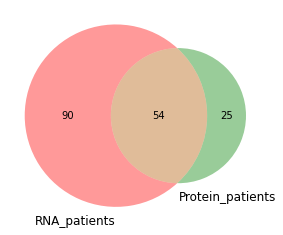

In [245]:
plot_venns(rna_count.columns,prt.columns,labels=['RNA_patients','Protein_patients'])

In [230]:
inter = set(rna_norm.index) & set(prt.index)
inter_pts = set(rna_norm.columns) & set(prt.columns)
len(inter_pts)


54

In [234]:
rna1 = rna_count.loc[inter,inter_pts]
rna1


,CPCG0398,CPCG0258,CPCG0336,CPCG0342,CPCG0435,CPCG0184,CPCG0388,CPCG0396,CPCG0463,CPCG0462,CPCG0335,CPCG0262,CPCG0265,CPCG0269,CPCG0361,CPCG0267,CPCG0348,CPCG0434,CPCG0100,CPCG0333,CPCG0392,CPCG0365,CPCG0334,CPCG0340,CPCG0458,CPCG0268,CPCG0331,CPCG0406,CPCG0344,CPCG0249,CPCG0183,CPCG0236,CPCG0266,CPCG0346,CPCG0248,CPCG0263,CPCG0459,CPCG0255,CPCG0397,CPCG0464,CPCG0366,CPCG0341,CPCG0256,CPCG0540,CPCG0324,CPCG0246,CPCG0250,CPCG0395,CPCG0457,CPCG0465,CPCG0339,CPCG0394,CPCG0345,CPCG0241
gene_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
TAPBP,4955.0,8837.0,7962.0,15803.0,39595.0,8391.0,3514.0,8683.0,10859.0,14989.0,26331.0,11622.0,10079.0,6671.0,8958.0,3469.0,2665.0,23529.0,20903.0,23550.0,12651.0,4315.0,14739.0,13314.0,31267.0,5542.0,22296.0,6347.0,6734.0,12521.0,12037.0,9115.0,11422.0,5175.0,12153.0,5515.0,10176.0,7653.0,6500.0,11498.0,8118.0,6398.0,10290.0,18202.0,20917.0,8147.0,8304.0,20368.0,19746.0,25154.0,9249.0,13392.0,5914.0,17238.0
SMPD1,1765.0,2409.0,1613.0,4060.0,5922.0,2041.0,695.0,3939.0,2826.0,3494.0,7271.0,4547.0,4162.0,1191.0,1075.0,875.0,914.0,5535.0,3087.0,5183.0,2875.0,609.0,4547.0,3701.0,6489.0,732.0,5947.0,1506.0,2202.0,1855.0,3898.0,2590.0,2366.0,1613.0,2233.0,1183.0,2907.0,1711.0,2166.0,3302.0,1524.0,2249.0,2202.0,3947.0,5513.0,1426.0,1289.0,4742.0,4020.0,3471.0,2742.0,6003.0,1179.0,2863.0
PCID2,2690.0,4011.0,3436.0,4169.0,7745.0,2869.0,1542.0,3953.0,5182.0,3893.0,4359.0,5618.0,3131.0,2543.0,1390.0,1232.0,1200.0,5167.0,2843.0,4360.0,4710.0,1925.0,5745.0,4961.0,5782.0,986.0,5204.0,2163.0,2402.0,3631.0,3047.0,2972.0,2929.0,2179.0,2220.0,1358.0,3820.0,1070.0,1893.0,3526.0,2644.0,3297.0,4203.0,4258.0,5610.0,2697.0,1886.0,3973.0,9135.0,3891.0,4450.0,4918.0,2845.0,3327.0
KTI12,287.0,323.0,235.0,477.0,900.0,210.0,167.0,335.0,327.0,422.0,518.0,437.0,308.0,154.0,142.0,94.0,118.0,555.0,418.0,526.0,367.0,114.0,432.0,491.0,520.0,106.0,561.0,170.0,233.0,347.0,349.0,290.0,265.0,150.0,252.0,148.0,236.0,140.0,161.0,314.0,264.0,263.0,239.0,354.0,618.0,173.0,184.0,429.0,553.0,375.0,375.0,338.0,162.0,226.0
ATP11B,16954.0,38421.0,43937.0,43080.0,58727.0,14428.0,14059.0,29278.0,31221.0,46473.0,79258.0,48207.0,38050.0,10424.0,16913.0,9674.0,12779.0,46641.0,35951.0,65118.0,45475.0,9136.0,51806.0,56450.0,37408.0,5200.0,68397.0,22723.0,22472.0,21561.0,30896.0,39298.0,35447.0,17918.0,29875.0,7187.0,23847.0,15405.0,12783.0,33889.0,23897.0,44320.0,22378.0,29692.0,74469.0,14798.0,16518.0,36476.0,192619.0,32382.0,33058.0,61806.0,11474.0,50708.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MBOAT7,1581.0,1894.0,1085.0,2625.0,5995.0,2283.0,800.0,3511.0,2286.0,3031.0,4170.0,2777.0,2318.0,1156.0,1144.0,644.0,839.0,5045.0,3040.0,3470.0,2503.0,842.0,3341.0,2702.0,5608.0,678.0,4174.0,1031.0,1424.0,2464.0,2467.0,2595.0,3226.0,1163.0,1650.0,1026.0,2665.0,1628.0,1435.0,2763.0,1154.0,1451.0,1928.0,4650.0,3732.0,1467.0,1189.0,2499.0,4346.0,2695.0,2087.0,4459.0,1065.0,2442.0
PTPN13,7452.0,20037.0,27043.0,17705.0,28581.0,10259.0,11442.0,41394.0,25601.0,23252.0,28314.0,30791.0,18477.0,11000.0,5772.0,6886.0,6489.0,27895.0,25103.0,34662.0,15664.0,8023.0,26268.0,14700.0,26395.0,6162.0,23085.0,11810.0,14452.0,20643.0,51910.0,41309.0,17076.0,10594.0,12546.0,6162.0,21702.0,18506.0,14348.0,33023.0,9738.0,17958.0,16087.0,41586.0,32790.0,13314.0,9803.0,12585.0,34806.0,21060.0,23209.0,28543.0,7187.0,21960.0
IVD,4180.0,11055.0,7597.0,6308.0,22556.0,4525.0,2768.0,14934.0,12536.0,12089.0,12618.0,6260.0,12436.0,6148.0,3186.0,2886.0,3306.0,12889.0,9138.0,8876.0,6985.0,3523.0,10915.0,15278.0,17563.0,2438.0,10852.0,4922.0,8533.0,9165.0,15022.0,13678.0,8384.0,5159.0,5454.0,3627.0,10376.0,6080.0,4512.0,10923.0,5464.0,8269.0,7043.0,12442.0,13569.0,5608.0,4120.0,11326.0,11962.0,8783.0,6380.0,8600.0,7006.0,7050.0


In [235]:
rna2 = rna_norm.loc[inter,inter_pts]
rna2

,CPCG0398,CPCG0258,CPCG0336,CPCG0342,CPCG0435,CPCG0184,CPCG0388,CPCG0396,CPCG0463,CPCG0462,CPCG0335,CPCG0262,CPCG0265,CPCG0269,CPCG0361,CPCG0267,CPCG0348,CPCG0434,CPCG0100,CPCG0333,CPCG0392,CPCG0365,CPCG0334,CPCG0340,CPCG0458,CPCG0268,CPCG0331,CPCG0406,CPCG0344,CPCG0249,CPCG0183,CPCG0236,CPCG0266,CPCG0346,CPCG0248,CPCG0263,CPCG0459,CPCG0255,CPCG0397,CPCG0464,CPCG0366,CPCG0341,CPCG0256,CPCG0540,CPCG0324,CPCG0246,CPCG0250,CPCG0395,CPCG0457,CPCG0465,CPCG0339,CPCG0394,CPCG0345,CPCG0241
gene_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
TAPBP,15.949195,21.018462,18.087998,32.014957,42.910734,27.519729,19.158223,17.902283,22.150244,30.674673,48.895002,21.634876,27.071838,30.026730,43.630860,26.192377,17.653661,35.035192,36.930954,40.601634,24.828311,23.141317,27.585391,25.487023,49.612278,40.298669,36.250135,26.264564,19.990234,28.785753,26.661895,20.767820,34.633658,23.919924,40.016524,29.892158,23.429988,28.779876,24.428210,24.077201,28.096710,17.382389,25.733443,35.468598,32.053366,28.269716,33.185895,42.160039,27.018191,47.328079,18.723115,27.618678,21.294562,41.149044
SMPD1,15.364285,15.495493,9.910036,22.243952,17.356675,18.102809,10.247332,21.963277,15.589543,19.337606,36.514369,22.891330,30.232559,14.497776,14.160015,17.866982,16.374057,22.289031,14.749968,24.166087,15.259233,8.832774,23.014874,19.160295,27.845387,14.394872,26.148884,16.853853,17.678061,11.533338,23.350013,15.959032,19.401865,20.163055,19.884612,17.340796,18.101416,17.401222,22.014522,18.699642,14.264742,16.524458,14.892664,20.800059,22.847294,13.381839,13.931300,26.545243,14.875642,17.661963,15.011473,33.480993,11.480842,18.482757
PCID2,104.501864,115.139776,94.210245,101.934670,101.303316,113.563201,101.464586,98.365337,127.574167,96.154215,97.692367,126.221086,101.498590,138.146568,81.709803,112.268513,95.939063,92.857318,60.622719,90.722651,111.562921,124.599027,129.771044,114.618952,110.728059,86.532200,102.116662,108.027632,86.058628,100.749169,81.455769,81.725896,107.189496,121.557936,88.223744,88.835832,106.153663,48.564356,85.862898,89.113326,110.444610,108.108747,126.858206,100.139915,103.756127,112.948724,90.967136,99.253956,150.855914,88.358778,108.722638,122.411612,123.636388,95.852251
KTI12,0.585748,0.487116,0.338509,0.612724,0.618446,0.436700,0.577302,0.437942,0.422931,0.547587,0.609902,0.515808,0.524547,0.439513,0.438535,0.450020,0.495625,0.523995,0.468265,0.575005,0.456690,0.387655,0.512659,0.595972,0.523166,0.488724,0.578334,0.446051,0.438565,0.505826,0.490153,0.418953,0.509490,0.439617,0.526126,0.508636,0.344541,0.333825,0.383652,0.416914,0.579354,0.453059,0.378978,0.437383,0.600477,0.380630,0.466249,0.563045,0.479773,0.447380,0.481336,0.441985,0.369859,0.342070
ATP11B,40.418845,67.683273,73.929087,64.640646,47.138963,35.047188,56.770734,44.709173,47.168505,70.440852,109.007615,66.466108,75.695763,34.751064,61.012662,54.099508,62.697621,51.438168,47.044569,83.151533,66.101550,36.289415,71.813781,80.037058,43.962669,28.005552,82.363794,69.644042,49.408663,36.713356,50.686420,66.316455,79.607192,61.341669,72.858527,28.852006,40.667300,42.907728,35.581781,52.560449,61.258509,89.182903,41.449606,42.852975,84.521340,38.031493,48.892277,55.921194,195.205872,45.126547,49.565160,94.407108,30.599818,89.653235
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MBOAT7,93.496321,82.764403,45.286172,97.703524,119.366461,137.563710,80.132925,132.995513,85.670727,113.962181,142.265866,94.976672,114.388211,95.596604,102.370842,89.335490,102.109718,138.016095,98.678612,109.913138,90.250728,82.963468,114.882832,95.030594,163.485220,90.577726,124.681684,78.384085,77.664454,104.075096,100.394388,108.627339,179.716566,98.763551,99.817651,102.170768,112.735249,112.480994,99.082674,106.299720,73.380349,72.426949,88.584369,166.473613,105.071133,93.523637,87.300269,95.035619,109.253259,9

In [238]:
prt2 = prt.loc[inter,inter_pts]
prt2

,CPCG0398,CPCG0258,CPCG0336,CPCG0342,CPCG0435,CPCG0184,CPCG0388,CPCG0396,CPCG0463,CPCG0462,CPCG0335,CPCG0262,CPCG0265,CPCG0269,CPCG0361,CPCG0267,CPCG0348,CPCG0434,CPCG0100,CPCG0333,CPCG0392,CPCG0365,CPCG0334,CPCG0340,CPCG0458,CPCG0268,CPCG0331,CPCG0406,CPCG0344,CPCG0249,CPCG0183,CPCG0236,CPCG0266,CPCG0346,CPCG0248,CPCG0263,CPCG0459,CPCG0255,CPCG0397,CPCG0464,CPCG0366,CPCG0341,CPCG0256,CPCG0540,CPCG0324,CPCG0246,CPCG0250,CPCG0395,CPCG0457,CPCG0465,CPCG0339,CPCG0394,CPCG0345,CPCG0241
Gene names,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
TAPBP,16100500.0,77285500.0,6.489900e+08,56669500.0,18465400.0,114292500.0,43158650.0,4912000.0,0.0,42471500.0,111096500.0,99027000.0,1.482100e+07,155310000.0,60891000.0,4.483440e+08,146210000.0,104257500.0,1.715800e+08,40429000.0,84120500.0,101775000.0,166481000.0,74599000.0,65176500.0,126977500.0,22102000.0,127753000.0,1.115755e+08,68379500.0,21725000.0,133149500.0,51969000.0,86818500.0,240850000.0,26587350.0,8609400.0,226209000.0,8753500.0,48189000.0,4.307300e+08,91206000.0,74112000.0,3733600.0,2.162590e+08,26948000.0,168740000.0,13811000.0,14205500.0,124902500.0,2.371860e+08,7696800.0,24952500.0,46629500.0
SMPD1,5230000.0,6862000.0,1.343000e+08,11004850.0,0.0,12695700.0,0.0,0.0,5485050.0,0.0,17134500.0,25284000.0,5.588650e+07,29038000.0,4242550.0,4.860045e+07,11196000.0,7566500.0,1.147250e+07,1093550.0,16578500.0,17144500.0,33160000.0,10673400.0,4679450.0,19010550.0,10740550.0,32612000.0,8.572900e+07,18900100.0,31423500.0,36956000.0,9987950.0,12134500.0,16847500.0,0.0,0.0,47547500.0,0.0,12998550.0,3.804300e+07,18406500.0,5368500.0,894350.0,1.157750e+08,6432200.0,45133000.0,2176200.0,0.0,6787000.0,4.280450e+07,0.0,0.0,44316000.0
PCID2,0.0,8137200.0,1.114150e+08,4697550.0,4460750.0,22682450.0,0.0,1407050.0,8369700.0,14583500.0,44561500.0,0.0,0.000000e+00,5541500.0,13294500.0,3.501800e+06,15624500.0,23008550.0,1.050150e+07,410390.0,22331000.0,13587700.0,26026950.0,10819000.0,1518600.0,14896500.0,11044000.0,3871900.0,1.164575e+08,33425000.0,11069200.0,46741000.0,8510350.0,0.0,1772600.0,0.0,1480700.0,0.0,2892350.0,15642450.0,3.196200e+07,8645700.0,26958000.0,1835450.0,1.246650e+08,4056900.0,57558000.0,5413350.0,0.0,0.0,1.706800e+07,155445.0,2835100.0,22148000.0
KTI12,0.0,0.0,0.000000e+00,0.0,0.0,4127700.0,0.0,0.0,0.0,0.0,5234000.0,0.0,0.000000e+00,0.0,0.0,0.000000e+00,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,17037050.0,0.0,7082000.0,5927950.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,4.019100e+07,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,13711000.0
ATP11B,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.921300e+07,0.0,0.0,0.000000e+00,6469500.0,0.0,0.000000e+00,0.0,6880000.0,0.0,16952500.0,7824500.0,0.0,0.0,5491650.0,48913500.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,32824000.0,0.0,0.0,0.000000e+00,0.0,0.0,554000.0,0.000000e+00,0.0,0.0,942350.0,394685.0,0.0,0.000000e+00,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MBOAT7,11726650.0,34476000.0,7.547650e+08,95486000.0,9470800.0,65042000.0,26494000.0,15522500.0,13361000.0,81641500.0,24766500.0,101475000.0,2.439250e+08,103824000.0,131900000.0,3.269655e+08,60009000.0,100648500.0,3.203400e+07,14743500.0,88257000.0,110915000.0,111719000.0,79259000.0,30493000.0,167970000.0,28948000.0,56422500.0,2.383565e+08,268480000.0,20583000.0,86280000.0,82029500.0,53819000.0,148800000.0,29170000.0,8909150.0,138120000.0,11093500.0,29459000.0,3.244450e+08,117825000.0,76840000.0,7130600.0,2.563950e+08,27950000.0,45151000.0,13794500.0,6044600.0,37527500.0,6.326850e+08,8536850.0,20567000.0,122100000.0
PTPN13,0.0,0.0,1.875100e+08,0.0,0.0,0.0,0.0,0.0,0.0,0.0,84770000.0,0.0,1.129880e+08,35993500.0,0.0,4.381150e+07,26642000.0,0.0,0.000000e+00,0.0,0.0,35384500.0,0.0,0.0,0.0,23652000.0,0.0,74450000.0,0.000000e+00,23505000.0,0.0,0.0

In [204]:
rna2

,SA506725,SA506730,SA530468,SA530470,SA530473,SA530485,SA530488,SA530492,SA530496,SA530500,SA530503,SA530506,SA530507,SA530512,SA530515,SA530519,SA530524,SA530527,SA530532,SA530535,SA530539,SA530542,SA530546,SA530550,SA530553,SA530558,SA530566,SA530567,SA530570,SA530574,...,SA598969,SA598970,SA598975,SA598980,SA598983,SA598986,SA598990,SA598995,SA598999,SA599001,SA599004,SA599005,SA599013,SA599015,SA601882,SA603156,SA603212,SA603229,SA603240,SA603250,SA603279,SA603285,SA603299,SA603412,SA603442,SA603505,SA603600,SA603621,SA603634,SA603652
gene_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
TAPBP,26.661895,27.519729,28.779876,25.733443,21.018462,21.634876,29.892158,27.071838,34.633658,26.192377,40.298669,44.952611,30.026730,32.053366,36.250135,27.585391,18.087998,18.723115,25.487023,17.382389,32.014957,19.990234,21.294562,23.919924,17.653661,25.698519,27.253855,20.767820,34.053537,25.775518,...,18.887559,23.429988,38.388885,26.264564,23.539227,27.002249,21.468067,30.003029,15.522118,27.794463,40.601634,46.025822,24.022080,29.534331,48.895002,24.428210,35.324955,47.481005,40.240900,34.382881,17.095186,26.324566,20.802568,49.612278,22.182174,29.600362,24.603640,38.518431,34.873453,29.868999
SMPD1,23.350013,18.102809,17.401222,14.892664,15.495493,22.891330,17.340796,30.232559,19.401865,17.866982,14.394872,19.230383,14.497776,22.847294,26.148884,23.014874,9.910036,15.011473,19.160295,16.524458,22.243952,17.678061,11.480842,20.163055,16.374057,17.308093,12.643598,15.959032,13.589736,11.642842,...,14.248316,18.101416,19.592866,16.853853,14.570492,18.114997,11.875914,17.002678,11.423803,17.079656,24.166087,24.208796,19.076354,15.255152,36.514369,22.014522,18.762587,30.547421,12.566082,19.955416,11.069570,15.987336,23.022799,27.845387,14.100541,21.832903,9.508334,15.061674,16.947182,10.834441
PCID2,81.455769,113.563201,48.564356,126.858206,115.139776,126.221086,88.835832,101.498590,107.189496,112.268513,86.532200,100.478194,138.146568,103.756127,102.116662,129.771044,94.210245,108.722638,114.618952,108.108747,101.934670,86.058628,123.636388,121.557936,95.939063,102.062650,124.266385,81.725896,146.204543,133.937823,...,109.042479,106.153663,126.906568,108.027632,85.468845,97.613380,104.548539,117.508866,128.094875,163.534242,90.722651,145.105574,137.818793,144.720370,97.692367,85.862898,120.420065,116.449338,93.884305,127.016991,156.198803,98.953607,98.586215,110.728059,100.238362,179.400715,128.684347,117.958037,121.984391,98.472720
KTI12,0.490153,0.436700,0.333825,0.378978,0.487116,0.515808,0.508636,0.524547,0.509490,0.450020,0.488724,0.431058,0.439513,0.600477,0.578334,0.512659,0.338509,0.481336,0.595972,0.453059,0.612724,0.438565,0.369859,0.439617,0.495625,0.406841,0.346985,0.418953,0.517756,0.716506,...,0.411631,0.344541,0.746617,0.446051,0.409505,0.446336,0.309743,0.496554,0.380222,0.435263,0.575005,0.441347,0.436747,0.476327,0.609902,0.383652,0.522244,0.622553,0.600964,0.362600,0.363634,0.447827,0.358650,0.523166,0.397885,0.457473,0.399887,0.444508,0.496347,0.421620
ATP11B,50.686420,35.047188,42.907728,41.449606,67.683273,66.466108,28.852006,75.695763,79.607192,54.099508,28.005552,32.329748,34.751064,84.521340,82.363794,71.813781,73.929087,49.565160,80.037058,89.182903,64.640646,49.408663,30.599818,61.341669,62.697621,42.874714,37.579292,66.316455,68.670858,44.959118,...,43.298953,40.667300,52.410412,69.644042,81.058758,42.249881,36.541250,36.281096,66.860800,50.205210,83.151533,31.846369,69.709640,50.529489,109.007615,35.581781,36.543334,47.566948,16.152935,40.899416,52.276669,61.290272,48.782063,43.962669,25.897392,49.264033,29.488310,39.961185,39.368183,25.632854
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MBOAT7,100.394388,137.563710,112.480994,88.584369,82.764403,94.976672,102.170768,114.388211,179.716566,89

In [240]:
((rna1.index == prt2.index) & (prt2.index == rna2.index)).all(), \
((rna1.columns == prt2.columns) & (prt2.columns == rna2.columns)).all()


(True, True)

In [244]:

db.exporting(rna1.T,'PRAD_CA_x_rna_count',outputdir='export')
db.exporting(rna2.T,'PRAD_CA_x_rna_norm',outputdir='export')
db.exporting(prt2.T,'PRAD_CA_x_protein',outputdir='export')



[08/23 07:48:19] overwritting 1 file with 54 lines at 
	[PROJECT_ROOT]/export/PRAD_CA_x_rna_count.dfx
[08/23 07:48:19] overwritting 1 file with 54 lines at 
	[PROJECT_ROOT]/export/PRAD_CA_x_rna_norm.dfx
[08/23 07:48:20] overwritting 1 file with 54 lines at 
	[PROJECT_ROOT]/export/PRAD_CA_x_protein.dfx


'[PROJECT_ROOT]/export/PRAD_CA_x_protein.dfx'